# Credit-risk modelling 

**Objectif :** prédire la probabilité qu'un client fasse défaut le mois suivant.



In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42



## 1. Chargement des données


In [ ]:
df = pd.read_excel("default of credit card clients.xls", header=1)   # nécessite xlrd

print(df.shape)
df.head()

Fichier : default_of_credit_card_clients.csv
(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Nettoyage

- Renommage : `PAY_0` → `PAY_1` (même mois que `BILL_AMT1` et `PAY_AMT1`) et la cible → `DEFAULT`.
- Suppression de `ID` : un numéro de client ne dit rien sur le risque.
- Doublons : supprimés, pour qu'un même client ne soit pas à la fois dans le train et le test.
- Codes non documentés : `EDUCATION` 0, 5, 6 → 4 (autres) ; `MARRIAGE` 0 → 3 (autres).

In [ ]:
df = df.rename(columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"})
df = df.drop(columns="ID")

print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons supprimés :", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print("Clients restants :", len(df))
print("Taux de défaut :", round(df["DEFAULT"].mean(), 3))

Valeurs manquantes : 0
Doublons supprimés : 35
Clients restants : 29965


Taux de défaut : 0.221


## 3. Exploration des données

### 3.1 Répartition de la cible

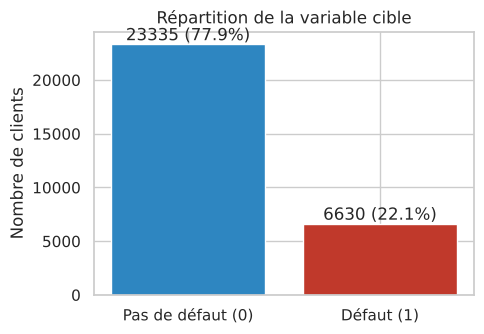

In [ ]:
counts = df["DEFAULT"].value_counts().sort_index()

plt.figure(figsize=(5, 3.5))
plt.bar(["Pas de défaut (0)", "Défaut (1)"], counts.values, color=["#239de8", "#c0392b"])
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
plt.ylabel("Nombre de clients")
plt.title("Répartition de la variable cible")
plt.tight_layout(); plt.show()

Les classes sont déséquilibrées : seulement 22 % des clients font défaut. Un modèle qui prédirait toujours « pas de défaut » aurait 78 % d'accuracy sans détecter un seul défaut. Il faudra donc corriger ce déséquilibre et ne pas se fier à l'accuracy.

### 3.2 Taux de défaut selon le retard de paiement en septembre (`PAY_1`)

Rappel des codes : -2 = aucune consommation, -1 = payé intégralement, 0 = paiement minimum, 1 à 8 = mois de retard.

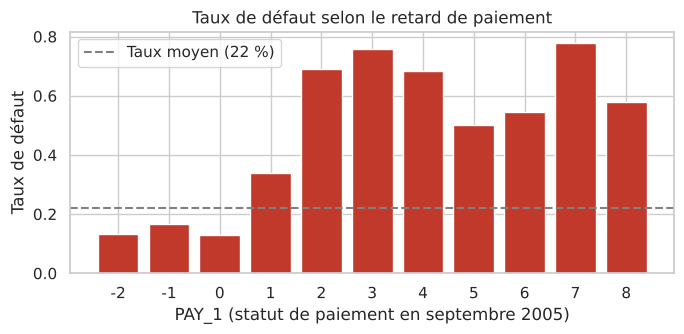

,taux_defaut,nb_clients
PAY_1,,
-2,0.132,2750
-1,0.168,5682
0,0.128,14737
1,0.340,3667
2,0.691,2666
3,0.758,322
4,0.684,76
5,0.500,26
6,0.545,11


In [ ]:
taux = df.groupby("PAY_1")["DEFAULT"].agg(taux_defaut="mean", nb_clients="size")

plt.figure(figsize=(7, 3.5))
plt.bar(taux.index.astype(str), taux["taux_defaut"], color="#c0392b")
plt.axhline(df["DEFAULT"].mean(), ls="--", c="grey", label="Taux moyen (22 %)")
plt.xlabel("PAY_1 (statut de paiement en septembre 2005)")
plt.ylabel("Taux de défaut")
plt.title("Taux de défaut selon le retard de paiement")
plt.legend(); plt.tight_layout(); plt.show()

taux.round(3)

Le retard de paiement est logiquement fortement lié au défaut : le taux de défaut est d'environ 13 % pour les clients qui paient le minimum (`PAY_1` = 0), mais monte à 34 % avec 1 mois de retard et à 69 % avec 2 mois.
### 3.3 Corrélations entre les variables

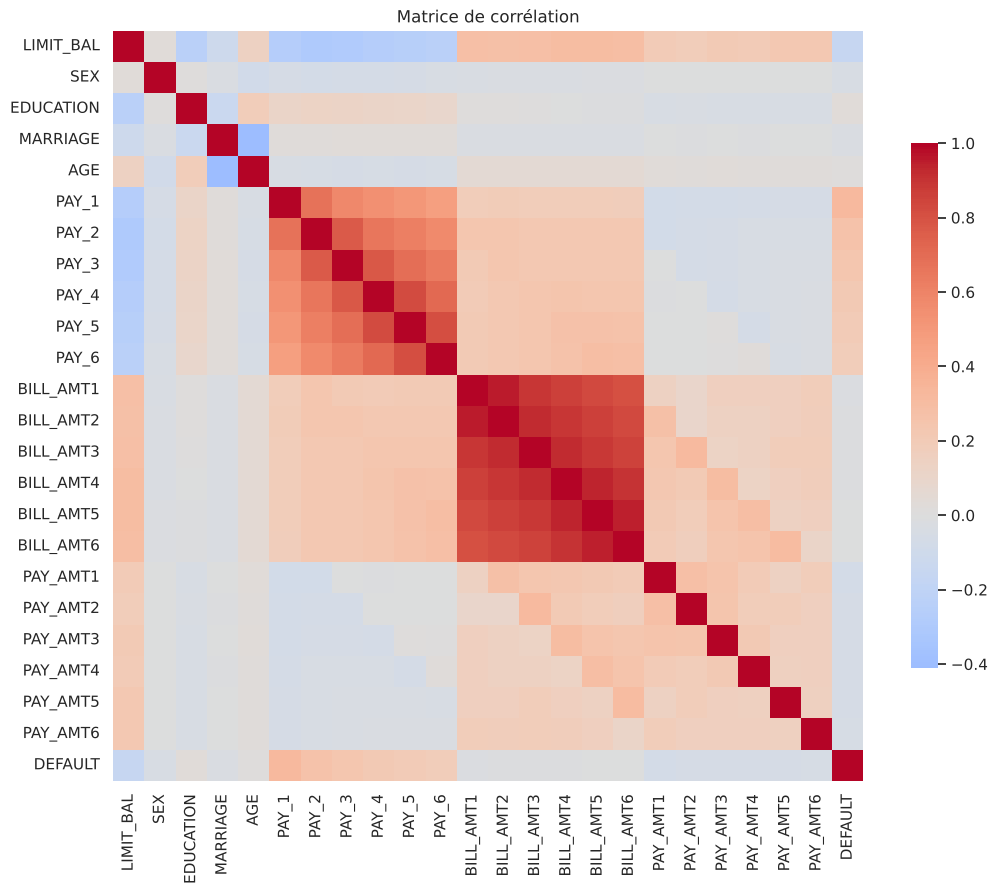

Variables les plus corrélées avec le défaut :


PAY_1        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
Name: DEFAULT, dtype: float64

In [ ]:
corr = df.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Matrice de corrélation")
plt.tight_layout(); plt.show()

print("Variables les plus corrélées avec le défaut :")
corr["DEFAULT"].drop("DEFAULT").sort_values(key=abs, ascending=False).head(8).round(3)

Ce qu'on observe 
- Les variables les plus liées au défaut sont les retards de paiement (`PAY_1` à `PAY_6`), surtout le mois le plus récent. Un plafond élevé (`LIMIT_BAL`) va de pair avec moins de défauts.
- Les montants des relevés (`BILL_AMT`) sont presque sans lien avec le défaut, mais très corrélés entre eux (bloc rouge) : d'un mois sur l'autre, le solde change peu.
- Les variables de profil (`SEX`, `AGE`, `EDUCATION`, `MARRIAGE`) sont peu prédictives.

C'est pourquoi on va faire du feature engineering : plutôt que les montants bruts, on va construire des ratios.

## 4. Feature engineering

On crée 4 variables qui résument le comportement du client sur les 6 mois :

| Variable | Calcul | Ce qu'elle mesure |
|------|------|------|
| `UTIL_MEAN` | moyenne de `BILL_AMT` / `LIMIT_BAL` | utilisation moyenne du crédit |
| `PAY_RATIO` | `PAY_AMT1` / `BILL_AMT2` (borné entre 0 et 1) | part de la facture d'août remboursée en septembre |
| `N_MONTHS_LATE` | nombre de mois avec `PAY_x` > 0 | fréquence des retards |
| `MAX_DELAY` | plus grand `PAY_x` | gravité du pire retard |

In [ ]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payamt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
pay_cols = [f"PAY_{i}" for i in range(1, 7)]

df["UTIL_MEAN"] = df[bill_cols].mean(axis=1) / df["LIMIT_BAL"]

# Si la facture est nulle ou négative, il n'y a rien à rembourser : ratio = 1
df["PAY_RATIO"] = np.where(df["BILL_AMT2"] > 0, df["PAY_AMT1"] / df["BILL_AMT2"], 1)
df["PAY_RATIO"] = df["PAY_RATIO"].clip(0, 1)

df["N_MONTHS_LATE"] = (df[pay_cols] > 0).sum(axis=1)
df["MAX_DELAY"] = df[pay_cols].max(axis=1).clip(lower=0)

# Lien des nouvelles variables avec le défaut
df[["UTIL_MEAN", "PAY_RATIO", "N_MONTHS_LATE", "MAX_DELAY", "PAY_1", "DEFAULT"]].corr()["DEFAULT"].round(3)

UTIL_MEAN        0.115
PAY_RATIO       -0.104
N_MONTHS_LATE    0.398
MAX_DELAY        0.370
PAY_1            0.325
DEFAULT          1.000
Name: DEFAULT, dtype: float64

## 5. Séparation train / test

80 % pour l'entraînement, 20 % pour le test. Le split est stratifié (`stratify=y`) : le train et le test gardent la même proportion de défauts (22 %).
Le test ne sera utilisé qu'à la toute fin.

In [ ]:
X = df.drop(columns="DEFAULT")
y = df["DEFAULT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train :", X_train.shape, "| taux de défaut :", round(y_train.mean(), 3))
print("Test  :", X_test.shape, "| taux de défaut :", round(y_test.mean(), 3))

Train : (23972, 27) | taux de défaut : 0.221


Test  : (5993, 27) | taux de défaut : 0.221


## 6. Encodage et mise à l'échelle

1. <u>One-hot encoding</u> de `SEX`, `EDUCATION`, `MARRIAGE` : ce sont des étiquettes, pas des grandeurs.
2. <u>Transformation log</u> de `LIMIT_BAL` et des `PAY_AMT` : ces montants sont très asymétriques (quelques valeurs énormes). Les `BILL_AMT` peuvent être négatifs, donc on ne leur applique pas le log.
3. <u>Standardisation</u> (moyenne 0, écart-type 1) : indispensable pour la régression logistique régularisée.

⚠️ Le `StandardScaler` est ajusté sur le train uniquement, puis appliqué au test, pour éviter toute Data leakage.

In [ ]:
def prepare(X):
    X = pd.get_dummies(X, columns=["SEX", "EDUCATION", "MARRIAGE"], drop_first=True, dtype=int)
    for col in ["LIMIT_BAL"] + payamt_cols:
        X[col] = np.log1p(X[col])
    return X

X_train_p = prepare(X_train)
X_test_p = prepare(X_test).reindex(columns=X_train_p.columns, fill_value=0)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_p)   # fit sur le train
X_test_s = scaler.transform(X_test_p)         # simple application sur le test

print("Nombre de variables après encodage :", X_train_s.shape[1])

Nombre de variables après encodage : 30


Fctn pour calculer toutes les métriques d'un coup.

In [ ]:
def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Modèle": name, "Seuil": threshold,
            "ROC-AUC": roc_auc_score(y_true, proba),
            "F1": f1_score(y_true, pred),
            "Précision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred),
            "Accuracy": accuracy_score(y_true, pred)}

results = []

## 7. Régression logistique

### 7.1 Baseline brute

Régression logistique par défaut, sans correction du déséquilibre, seuil 0,5.

In [ ]:
lr_base = LogisticRegression(max_iter=1000)
lr_base.fit(X_train_s, y_train)
p_base = lr_base.predict_proba(X_test_s)[:, 1]

results.append(evaluate("LR baseline", y_test, p_base))
pd.DataFrame(results).round(3)

,Modèle,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
0,LR baseline,0.5,0.758,0.414,0.655,0.303,0.81


L'accuracy semble ok, mais le recall est faible : le modèle rate la majorité des défauts, car il privilégie la classe majoritaire.

### 7.2 Correction du déséquilibre : `class_weight="balanced"`

Avec 22 % de défauts, chaque erreur sur un défaut reçoit un poids environ 3,5 fois plus élevé dans la fonction de perte. Le modèle est donc davantage pénalisé quand il rate un défaut.

In [ ]:
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_bal.fit(X_train_s, y_train)
p_bal = lr_bal.predict_proba(X_test_s)[:, 1]

results.append(evaluate("LR balanced", y_test, p_bal))
pd.DataFrame(results).round(3)

,Modèle,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
0,LR baseline,0.5,0.758,0.414,0.655,0.303,0.81
1,LR balanced,0.5,0.761,0.512,0.438,0.617,0.74


## 8. Choix du seuil de décision

Le seuil de 0,5 n'est pas unique. ON peut l'optimiser en cherchant celui qui va maximiser F1.

Il est possibl de faire une validation croisée à 5 plis sur le train avec `cross_val_predict` : le train est coupé en 5 morceaux, et chaque client reçoit une probabilité calculée par un modèle entraîné sur les 4 autres morceaux, donc qui ne l'a pas vu.

Seuil retenu : 0.62


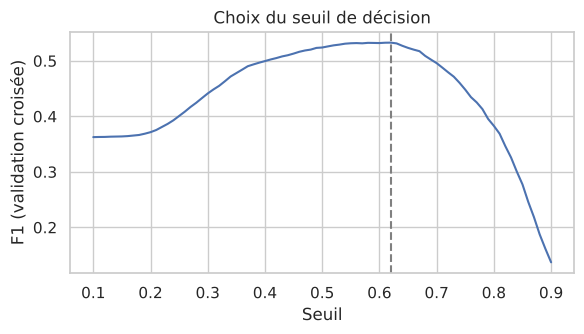

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
best_lr = lr_bal
p_train_cv = cross_val_predict(best_lr, X_train_s, y_train, cv=cv, method="predict_proba")[:, 1]

seuils = np.arange(0.10, 0.91, 0.01)
f1s = [f1_score(y_train, (p_train_cv >= s).astype(int)) for s in seuils]
best_seuil = round(float(seuils[np.argmax(f1s)]), 2)
print("Seuil retenu :", best_seuil)

plt.figure(figsize=(6, 3.5))
plt.plot(seuils, f1s)
plt.axvline(best_seuil, ls="--", c="grey")
plt.xlabel("Seuil"); plt.ylabel("F1 (validation croisée)")
plt.title("Choix du seuil de décision")
plt.tight_layout(); plt.show()

## 9. Évaluation finale sur le test

In [ ]:
p_best = best_lr.predict_proba(X_test_s)[:, 1]
results.append(evaluate("LR balanced + seuil optimisé", y_test, p_best, best_seuil))

res = pd.DataFrame(results).set_index("Modèle").round(3)
res

,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785


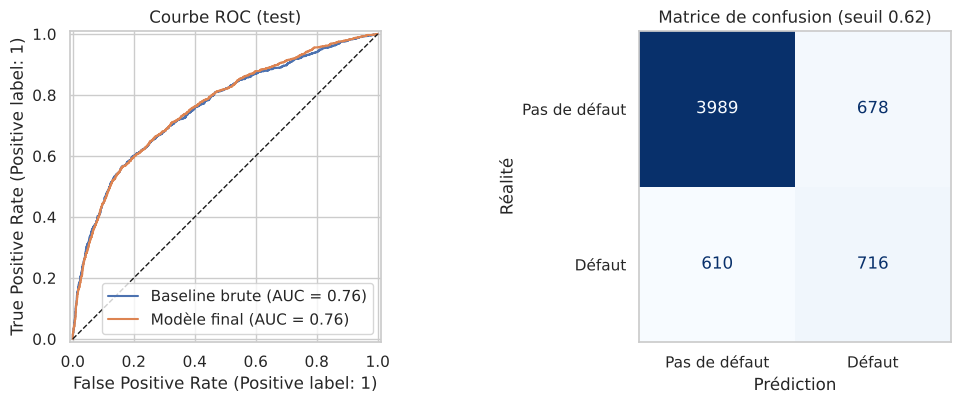

Défauts détectés : 716 sur 1326 (54%)


Défauts manqués : 610 | Fausses alertes : 678


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

RocCurveDisplay.from_predictions(y_test, p_base, name="Baseline brute", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, p_best, name="Modèle final", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("Courbe ROC (test)")

cm = confusion_matrix(y_test, (p_best >= best_seuil).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["Pas de défaut", "Défaut"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_xlabel("Prédiction"); axes[1].set_ylabel("Réalité"); axes[1].grid(False)
axes[1].set_title(f"Matrice de confusion (seuil {best_seuil})")

plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Défauts détectés : {tp} sur {tp + fn} ({tp / (tp + fn):.0%})")
print(f"Défauts manqués : {fn} | Fausses alertes : {fp}")

## 10. Interprétation des coefficients

Les variables sont standardisées : quand une variable augmente d'un écart-type, la cote du défaut est multipliée par $e^{\beta}$ (cours 4).
- coefficient positif (rouge) → augmente le risque ;
- coefficient négatif (vert) → réduit le risque.

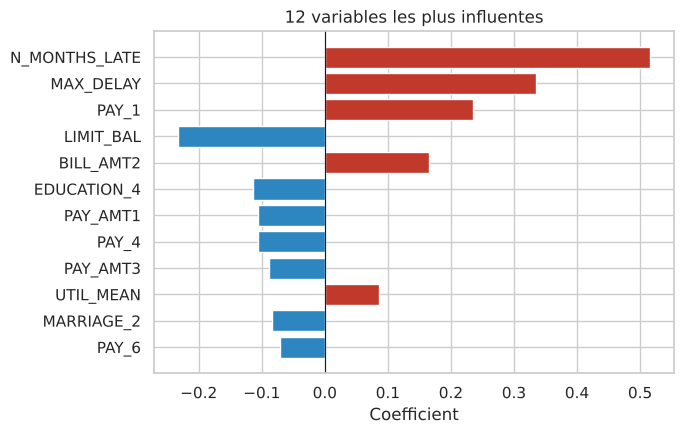

,variable,coef,odds_ratio
0,N_MONTHS_LATE,0.516,1.676
1,MAX_DELAY,0.335,1.398
2,PAY_1,0.234,1.264
3,LIMIT_BAL,-0.233,0.792
4,BILL_AMT2,0.166,1.181
5,EDUCATION_4,-0.114,0.893
6,PAY_AMT1,-0.107,0.899
7,PAY_4,-0.105,0.900
8,PAY_AMT3,-0.089,0.915
9,UTIL_MEAN,0.087,1.091


In [ ]:
coefs = pd.DataFrame({"variable": X_train_p.columns, "coef": best_lr.coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index)

top = coefs.head(12).iloc[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top["variable"], top["coef"], color=np.where(top["coef"] > 0, "#d71a30", "#2e86c1"))
plt.axvline(0, c="k", lw=0.8)
plt.xlabel("Coefficient")
plt.title("12 variables les plus influentes")
plt.tight_layout(); plt.show()

coefs.head(12).round(3).reset_index(drop=True)

Lecture : les variables de retard de paiement (`N_MONTHS_LATE`, `MAX_DELAY`, `PAY_1`) augmentent le plus le risque. Un plafond élevé (`LIMIT_BAL`) et des remboursements importants (`PAY_AMT`) le réduisent. Le feature engineering est plus qu'utile

## Résultats finaux

Ces scores servent de base line : les autres modèles devront faire mieux.

In [ ]:
pd.DataFrame(results).set_index("Modèle").round(3)

,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785


---
# Partie 2 — K plus proches voisins (KNN)

On reprend **exactement** les données préparées plus haut : même nettoyage, mêmes 4 variables construites, même split train / test stratifié et mêmes matrices standardisées `X_train_s` / `X_test_s`. Les résultats sont donc directement comparables à ceux de la régression logistique et sont ajoutés à la même liste `results`.

**Principe.** Pour un nouveau client, le KNN cherche les *k* clients du train qui lui ressemblent le plus (les plus proches au sens d'une distance calculée sur les variables) et regarde combien d'entre eux ont fait défaut :

$$\widehat{PD} = \frac{\text{nombre de voisins en défaut}}{k}$$

Le modèle donne donc directement une **probabilité de défaut** pour chaque client, transformée ensuite en décision (défaut / pas de défaut) avec un seuil.

**Pourquoi le prétraitement de la partie 1 est indispensable ici :**
- **Standardisation** : sans elle, `LIMIT_BAL` (jusqu'à 1 000 000) écraserait `PAY_1` (de -2 à 8) dans le calcul de la distance.
- **One-hot encoding** : avec les codes bruts, `EDUCATION` = 1 et 4 seraient « plus éloignés » que 1 et 2, ce qui n'a pas de sens.
- **Log des montants** : il limite l'effet des quelques montants énormes sur la distance.
- Le KNN n'a pas d'option `class_weight` : le déséquilibre des classes est géré par le **choix du seuil**, comme pour la régression logistique.

In [18]:
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import roc_curve, brier_score_loss
from sklearn.inspection import permutation_importance

# Couleurs utilisées pour comparer les modèles dans les graphiques
COL_KNN, COL_LR, COL_LR_BASE = "#257de0", "#f47230", "#00b894"


## 11. Modèle KNN

### 11.1 KNN « par défaut » (k = 5)

Paramètres par défaut de scikit-learn : 5 voisins, distance euclidienne, seuil 0,5.

In [19]:
knn_base = KNeighborsClassifier()          # k = 5, distance euclidienne
knn_base.fit(X_train_s, y_train)
p_knn_base = knn_base.predict_proba(X_test_s)[:, 1]

print("Valeurs possibles de la probabilité :", np.unique(p_knn_base))
results.append(evaluate("KNN k=5", y_test, p_knn_base))
pd.DataFrame(results).set_index("Modèle").round(3)

Valeurs possibles de la probabilité : [0.  0.2 0.4 0.6 0.8 1. ]


,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785
KNN k=5,0.50,0.704,0.408,0.514,0.339,0.783


Avec seulement 5 voisins, la probabilité de défaut ne peut prendre que 6 valeurs (0 ; 0,2 ; … ; 1) : le classement des clients est grossier et très sensible au bruit (sur-apprentissage). L'AUC est nettement en dessous de la régression logistique. Il faut régler *k*.

### 11.2 Choix des hyperparamètres par validation croisée

Trois hyperparamètres sont testés :

| Hyperparamètre | Valeurs testées | Effet |
|------|------|------|
| `n_neighbors` (*k*) | 5 à 400 | petit *k* : modèle très flexible, forte variance ; grand *k* : probabilités lissées, plus stables |
| `weights` | `uniform`, `distance` | chaque voisin compte pareil, ou les plus proches comptent davantage |
| `p` | 1, 2 | 1 = distance de Manhattan, 2 = distance euclidienne |

- **Critère :** ROC-AUC, qui ne dépend pas du seuil.
- **Validation croisée à 5 plis sur le train**, avec les mêmes plis `cv` que pour la régression logistique. Le test n'est pas utilisé.

⏱ Environ 1 minute.

In [20]:
param_grid = {
    "n_neighbors": [5, 15, 25, 50, 75, 100, 150, 200, 250, 300, 400],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}

grid = GridSearchCV(KNeighborsClassifier(), param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train_s, y_train)

print("Meilleurs hyperparamètres :", grid.best_params_)
print("ROC-AUC en validation croisée :", round(grid.best_score_, 3))

Meilleurs hyperparamètres : {'n_neighbors': 250, 'p': 1, 'weights': 'uniform'}
ROC-AUC en validation croisée : 0.774


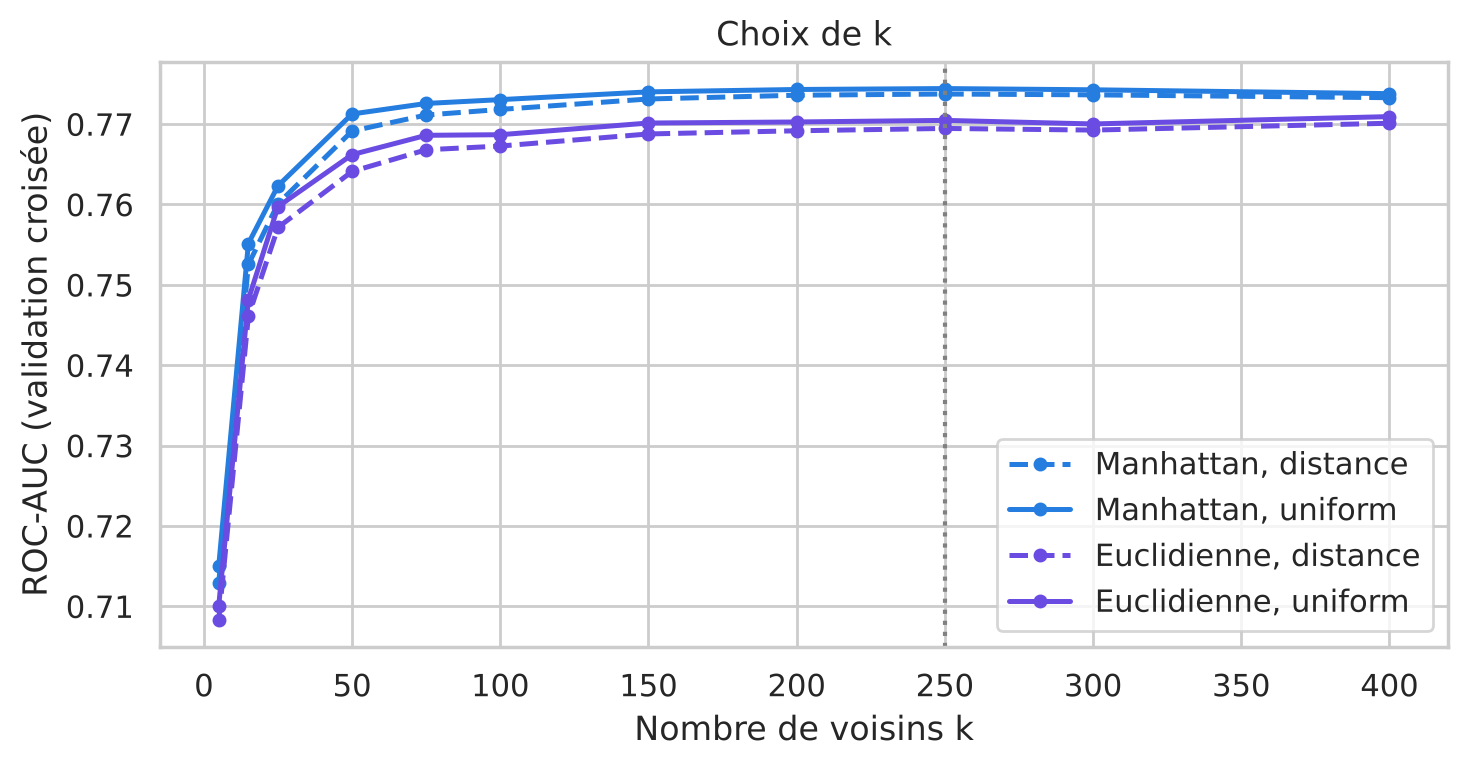

In [21]:
cv_knn = pd.DataFrame(grid.cv_results_["params"])
cv_knn["auc"] = grid.cv_results_["mean_test_score"]

plt.figure(figsize=(7.5, 4))
for (p, w), g in cv_knn.groupby(["p", "weights"]):
    plt.plot(g["n_neighbors"], g["auc"], marker="o", ms=4, lw=1.8,
             color=COL_KNN if p == 1 else "#6a4ce2", ls="-" if w == "uniform" else "--",
             label=f"{'Manhattan' if p == 1 else 'Euclidienne'}, {w}")
plt.axvline(grid.best_params_["n_neighbors"], ls=":", c="grey")
plt.xlabel("Nombre de voisins k"); plt.ylabel("ROC-AUC (validation croisée)")
plt.title("Choix de k")
plt.legend(); plt.tight_layout(); plt.show()

L'AUC augmente fortement jusqu'à *k* ≈ 100 puis plafonne : au-delà, ajouter des voisins ne change presque plus rien. La distance de Manhattan fait un peu mieux que la distance euclidienne : elle est moins dominée par un grand écart sur une seule variable. La pondération uniforme est légèrement meilleure que la pondération par la distance.

Entre *k* = 100 et *k* = 400, les écarts d'AUC sont bien plus petits que la variation d'un pli à l'autre : toutes ces valeurs se valent, et `GridSearchCV` retient simplement le maximum. Un grand *k* ne crée pas de sur-apprentissage, au contraire. Dans un KNN, le sur-apprentissage vient d'un **petit** *k* (le modèle colle aux quelques clients les plus proches). Un grand *k* lisse les probabilités ; le risque est plutôt le sous-apprentissage pour les profils rares, dont les voisins deviennent moins semblables.

On évalue ce modèle réglé sur le test, au seuil 0,5 :

In [22]:
knn_all = grid.best_estimator_            # déjà ré-entraîné sur tout le train par GridSearchCV
p_knn_all = knn_all.predict_proba(X_test_s)[:, 1]

results.append(evaluate("KNN optimisé (30 variables)", y_test, p_knn_all))
pd.DataFrame(results).set_index("Modèle").round(3)

,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785
KNN k=5,0.50,0.704,0.408,0.514,0.339,0.783
KNN optimisé (30 variables),0.50,0.763,0.385,0.684,0.268,0.811


Au seuil de 0,5, le recall est faible : comme la LR baseline, le KNN « suit » la classe majoritaire. Ce sera corrigé au 11.4 par le choix du seuil. L'AUC, elle, est déjà au niveau de la régression logistique.

### 11.3 Sélection des variables

Dans le KNN, **toutes les variables pèsent autant dans la distance**. Or l'exploration (section 3.3) a montré que les variables de profil (`SEX`, `AGE`, `EDUCATION`, `MARRIAGE`) et les `BILL_AMT` n'ont presque aucun lien avec le défaut. Pour le KNN, une variable inutile ajoute du bruit : deux clients au comportement de paiement identique peuvent être jugés « éloignés » simplement parce qu'ils n'ont pas le même âge. Plus il y a de variables inutiles, moins la notion de « voisin » a de sens (fléau de la dimension).

Nous comparons deux méthodes de sélection, toutes deux calculées **sur le train uniquement** :
1. un **filtre par corrélation** : simple et rapide, mais il juge chaque variable isolément ;
2. une **sélection pas à pas** : elle construit un ensemble de variables en tenant compte de ce que chacune apporte aux autres.

#### 11.3.1 Filtre par corrélation

On garde les variables dont la corrélation avec le défaut (en valeur absolue) dépasse un seuil. Le seuil est choisi par validation croisée (AUC), avec les hyperparamètres trouvés au 11.2.

In [23]:
corr_train = X_train_p.corrwith(y_train).abs().sort_values(ascending=False)

filtre = []
for s in [0, 0.03, 0.05, 0.15, 0.25]:
    cols = corr_train[corr_train >= s].index
    idx = [X_train_p.columns.get_loc(c) for c in cols]
    auc = cross_val_score(clone(knn_all), X_train_s[:, idx], y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
    filtre.append({"Seuil |corr|": s, "Nb variables": len(cols), "ROC-AUC (CV)": auc})

filtre = pd.DataFrame(filtre)
seuil_corr = filtre.loc[filtre["ROC-AUC (CV)"].idxmax(), "Seuil |corr|"]
auc_filtre = filtre.loc[filtre["ROC-AUC (CV)"].idxmax(), "ROC-AUC (CV)"]
vars_corr = list(corr_train[corr_train >= seuil_corr].index)

print("Seuil de corrélation retenu :", seuil_corr, f"→ {len(vars_corr)} variables gardées")
print("Variables retirées :", sorted(set(X_train_p.columns) - set(vars_corr)))
filtre.round(4)

Seuil de corrélation retenu : 0.05 → 17 variables gardées
Variables retirées : ['AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_2', 'MARRIAGE_3', 'SEX_2']


,Seuil |corr|,Nb variables,ROC-AUC (CV)
0,0.00,30,0.7744
1,0.03,20,0.7772
2,0.05,17,0.7776
3,0.15,11,0.7754
4,0.25,4,0.7360


Les variables retirées sont exactement celles que l'exploration jugeait peu prédictives : profil du client et montants des relevés. On garde les retards de paiement (`PAY_x`, `N_MONTHS_LATE`, `MAX_DELAY`), le plafond, les remboursements et les ratios que nous avons construits (`UTIL_MEAN`, `PAY_RATIO`).

Le seuil exact compte peu : toutes les variables de comportement ont une corrélation supérieure à 0,10, toutes les variables de profil et les `BILL_AMT` une corrélation inférieure à 0,05. N'importe quel seuil entre les deux garde les mêmes variables.

**Limite de ce filtre :** il juge chaque variable seule. Il ne voit pas la **redondance** (`PAY_1`, `MAX_DELAY` et `N_MONTHS_LATE` mesurent toutes le retard) ni la **complémentarité** (une variable peu liée au défaut à elle seule peut être utile combinée à d'autres).

On refait la recherche d'hyperparamètres sur ces variables, car le meilleur *k* peut changer quand la distance change. ⏱ Environ 1 minute.

In [24]:
idx_corr = [X_train_p.columns.get_loc(c) for c in vars_corr]
X_train_corr, X_test_corr = X_train_s[:, idx_corr], X_test_s[:, idx_corr]

grid_corr = GridSearchCV(KNeighborsClassifier(), param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_corr.fit(X_train_corr, y_train)
print("Meilleurs hyperparamètres :", grid_corr.best_params_)
print(f"ROC-AUC (CV) : {grid_corr.best_score_:.3f} avec {len(vars_corr)} variables")

p_knn_corr = grid_corr.best_estimator_.predict_proba(X_test_corr)[:, 1]
results.append(evaluate(f"KNN + filtre corrélation ({len(vars_corr)} var.)", y_test, p_knn_corr))
pd.DataFrame(results).set_index("Modèle").round(3)

Meilleurs hyperparamètres : {'n_neighbors': 150, 'p': 1, 'weights': 'uniform'}
ROC-AUC (CV) : 0.778 avec 17 variables


,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785
KNN k=5,0.50,0.704,0.408,0.514,0.339,0.783
KNN optimisé (30 variables),0.50,0.763,0.385,0.684,0.268,0.811
KNN + filtre corrélation (17 var.),0.50,0.769,0.461,0.643,0.359,0.814


#### 11.3.2 Sélection pas à pas

**Principe :** on part de zéro variable. À chaque étape, on essaie d'ajouter chacune des variables restantes et on garde celle qui fait **le plus monter l'AUC** en validation croisée (5 plis sur le train, KNN réglé au 11.2).

Contrairement au filtre, chaque variable est jugée **avec celles déjà choisies** :
- une variable redondante n'apporte presque rien et n'est pas retenue ;
- une variable peu liée au défaut à elle seule, mais complémentaire des autres, peut l'être.

C'est l'algorithme de `SequentialFeatureSelector(direction="forward")` de scikit-learn. Nous l'écrivons nous-mêmes pour garder l'AUC et la variable ajoutée à chaque étape, que scikit-learn ne fournit pas : elles servent à tracer la courbe et à justifier le nombre de variables retenu. On s'arrête à 12 variables, l'AUC plafonnant bien avant.

⏱ Environ 5 à 10 minutes selon l'ordinateur (environ 300 validations croisées).

In [25]:
toutes_vars = list(X_train_p.columns)
choisies, restantes, chemin = [], toutes_vars.copy(), []

for etape in range(12):
    scores = {}
    for v in restantes:                      # on essaie d'ajouter chaque variable restante
        idx = [toutes_vars.index(c) for c in choisies + [v]]
        s = cross_val_score(clone(knn_all), X_train_s[:, idx], y_train,
                            cv=cv, scoring="roc_auc", n_jobs=-1)
        scores[v] = (s.mean(), s.std())
    meilleure = max(scores, key=lambda v: scores[v][0])   # celle qui fait le plus monter l'AUC
    choisies.append(meilleure); restantes.remove(meilleure)
    chemin.append({"nb_variables": etape + 1, "ajout": meilleure,
                   "auc": scores[meilleure][0], "std": scores[meilleure][1]})
    print(f"Étape {etape + 1:2d} : + {meilleure:<14s} AUC (CV) = {scores[meilleure][0]:.4f}")

chemin = pd.DataFrame(chemin)

Étape  1 : + N_MONTHS_LATE  AUC (CV) = 0.7279


Étape  2 : + UTIL_MEAN      AUC (CV) = 0.7558


Étape  3 : + PAY_1          AUC (CV) = 0.7680


Étape  4 : + BILL_AMT1      AUC (CV) = 0.7752


Étape  5 : + BILL_AMT5      AUC (CV) = 0.7786


Étape  6 : + MAX_DELAY      AUC (CV) = 0.7806


... (2 outputs left out)

Étape  9 : + LIMIT_BAL      AUC (CV) = 0.7825


Étape 10 : + PAY_AMT3       AUC (CV) = 0.7830


Étape 11 : + PAY_6          AUC (CV) = 0.7831


Étape 12 : + PAY_RATIO      AUC (CV) = 0.7830


**Combien de variables garder ? La règle d'un écart-type.** On prend le **plus petit nombre de variables dont l'AUC n'est pas significativement inférieure à la meilleure**, c'est-à-dire à moins d'une erreur-type du maximum (erreur-type = écart-type entre les plis / √5). C'est une règle classique (Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, §7.10) : entre plusieurs modèles qui se valent, on prend le plus simple.

Meilleure AUC : 0.7831 avec 11 variables (erreur-type 0.0042)
Règle d'un écart-type → 6 variables : ['N_MONTHS_LATE', 'UTIL_MEAN', 'PAY_1', 'BILL_AMT1', 'BILL_AMT5', 'MAX_DELAY']


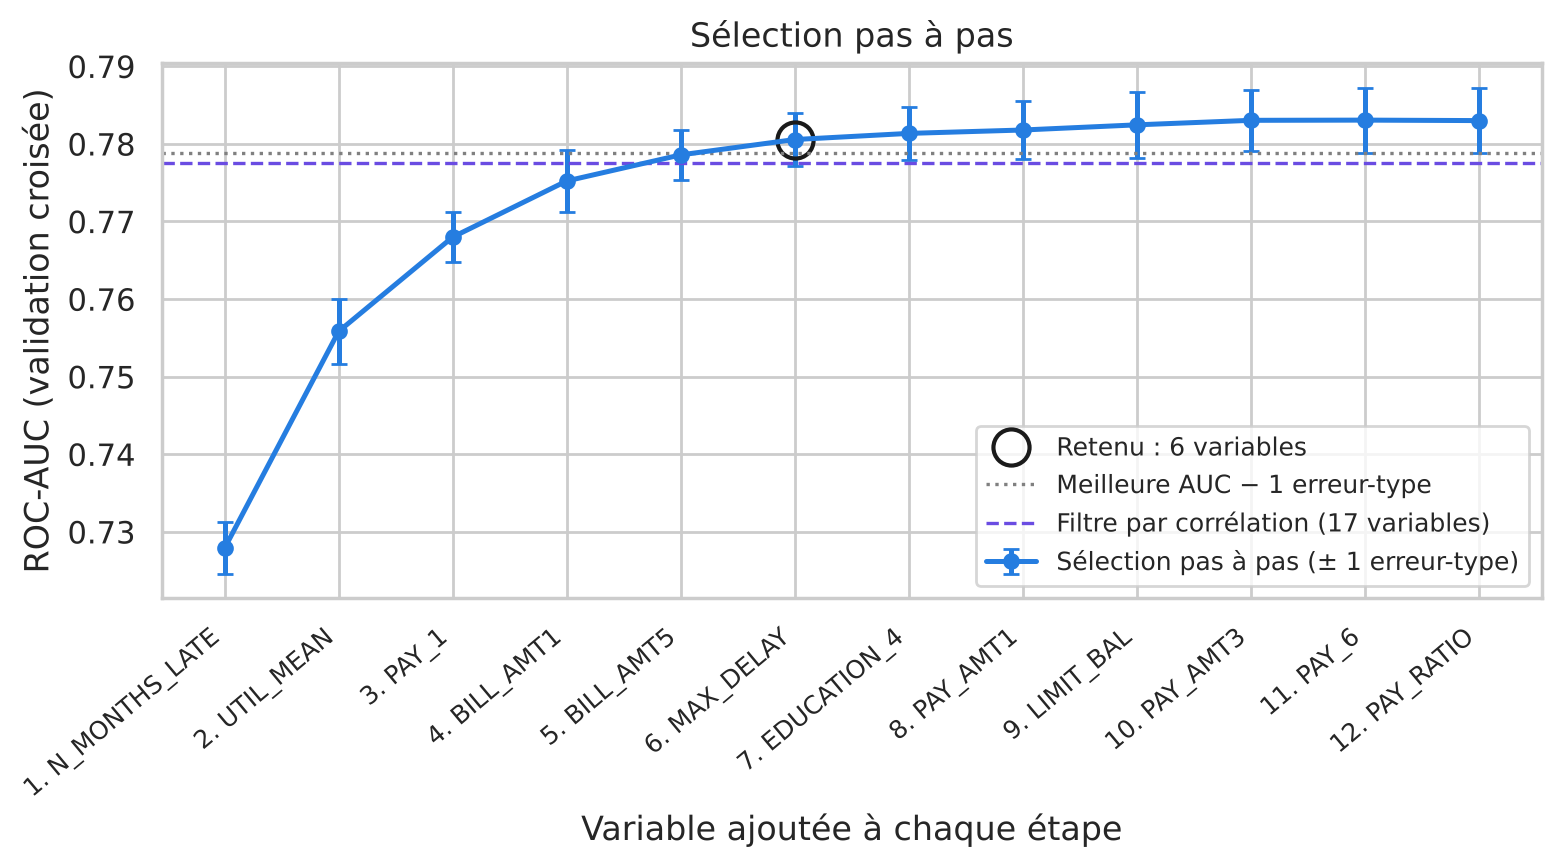

In [26]:
n_plis = cv.get_n_splits()
i_max = chemin["auc"].idxmax()
erreur_type = chemin.loc[i_max, "std"] / np.sqrt(n_plis)
seuil_1se = chemin.loc[i_max, "auc"] - erreur_type
nb_vars = int(chemin.loc[chemin["auc"] >= seuil_1se, "nb_variables"].min())
vars_sfs = choisies[:nb_vars]

print(f"Meilleure AUC : {chemin.loc[i_max, 'auc']:.4f} avec {chemin.loc[i_max, 'nb_variables']} variables "
      f"(erreur-type {erreur_type:.4f})")
print(f"Règle d'un écart-type → {nb_vars} variables : {vars_sfs}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(chemin["nb_variables"], chemin["auc"], yerr=chemin["std"] / np.sqrt(n_plis),
            color=COL_KNN, marker="o", ms=5, lw=1.8, capsize=3, label="Sélection pas à pas (± 1 erreur-type)")
ax.plot(nb_vars, chemin.loc[nb_vars - 1, "auc"], "o", ms=13, mfc="none", mec="k", mew=1.5,
        label=f"Retenu : {nb_vars} variables")
ax.axhline(seuil_1se, color="grey", ls=":", lw=1.2, label="Meilleure AUC − 1 erreur-type")
ax.axhline(auc_filtre, color="#6a4ce2", ls="--", lw=1.2, label=f"Filtre par corrélation ({len(vars_corr)} variables)")
ax.set_xticks(chemin["nb_variables"])
ax.set_xticklabels([f"{n}. {v}" for n, v in zip(chemin["nb_variables"], chemin["ajout"])],
                   rotation=40, ha="right", fontsize=9)
ax.set_xlabel("Variable ajoutée à chaque étape"); ax.set_ylabel("ROC-AUC (validation croisée)")
ax.set_title("Sélection pas à pas")
ax.legend(loc="lower right", fontsize=9); plt.tight_layout(); plt.show()

**Lecture :**
- L'AUC monte vite sur les premières variables puis plafonne : de la 6ᵉ à la 11ᵉ variable, elle ne gagne plus qu'environ 0,0025, moins qu'une erreur-type (0,0042). La règle d'un écart-type retient donc **6 variables** : `N_MONTHS_LATE`, `UTIL_MEAN`, `PAY_1`, `BILL_AMT1`, `BILL_AMT5` et `MAX_DELAY`.
- Avec ces 6 variables, la sélection pas à pas fait déjà mieux en validation croisée que le filtre avec 17 variables (ligne violette).
- La sélection tient compte des complémentarités. Elle prend `N_MONTHS_LATE` en premier, puis passe à d'autres informations (utilisation du crédit, retard récent, montants des relevés) avant de revenir à une autre mesure du retard (`MAX_DELAY`).
- Elle retient `BILL_AMT1` et `BILL_AMT5`, que le filtre avait écartées car peu liées au défaut à elles seules. Combinées à `UTIL_MEAN`, elles renseignent probablement sur le niveau de la dette et sur son évolution entre mai et septembre. À l'inverse, `LIMIT_BAL` n'arrive qu'en 9ᵉ position : son information est en partie déjà portée par `UTIL_MEAN` (solde moyen / plafond) et par les `BILL_AMT`.

⚠️ L'AUC de la sélection en validation croisée est un peu optimiste : on a comparé environ 300 combinaisons de variables sur les mêmes plis et gardé la meilleure, donc on profite un peu du hasard. Seul le test, jamais utilisé pour choisir, donne une estimation honnête.

On refait la recherche d'hyperparamètres sur ces 6 variables. ⏱ Environ 30 secondes.

In [27]:
idx_sfs = [X_train_p.columns.get_loc(c) for c in vars_sfs]
X_train_sfs, X_test_sfs = X_train_s[:, idx_sfs], X_test_s[:, idx_sfs]

grid_sfs = GridSearchCV(KNeighborsClassifier(), param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_sfs.fit(X_train_sfs, y_train)
print("Meilleurs hyperparamètres :", grid_sfs.best_params_)
print(f"ROC-AUC (CV) : {grid_sfs.best_score_:.3f} avec {len(vars_sfs)} variables "
      f"(filtre : {grid_corr.best_score_:.3f} avec {len(vars_corr)} variables)")
print(f"Écart-type de l'AUC entre les 5 plis : {grid_sfs.cv_results_['std_test_score'][grid_sfs.best_index_]:.3f}")

p_knn_sfs = grid_sfs.best_estimator_.predict_proba(X_test_sfs)[:, 1]
results.append(evaluate(f"KNN + sélection pas à pas ({len(vars_sfs)} var.)", y_test, p_knn_sfs))
pd.DataFrame(results).set_index("Modèle").round(3)

Meilleurs hyperparamètres : {'n_neighbors': 250, 'p': 1, 'weights': 'uniform'}
ROC-AUC (CV) : 0.781 avec 6 variables (filtre : 0.778 avec 17 variables)
Écart-type de l'AUC entre les 5 plis : 0.008


,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785
KNN k=5,0.50,0.704,0.408,0.514,0.339,0.783
KNN optimisé (30 variables),0.50,0.763,0.385,0.684,0.268,0.811
KNN + filtre corrélation (17 var.),0.50,0.769,0.461,0.643,0.359,0.814
KNN + sélection pas à pas (6 var.),0.50,0.766,0.471,0.664,0.365,0.819


#### 11.3.3 Choix de la sélection

| | Filtre par corrélation | Sélection pas à pas |
|------|------|------|
| Nombre de variables | 17 | **6** |
| ROC-AUC en validation croisée | 0,778 | 0,781 |
| ROC-AUC sur le test (pour information) | 0,769 | 0,766 |

Sur le test, la sélection pas à pas fait légèrement moins bien que le filtre, alors qu'elle faisait mieux en validation croisée : c'est l'optimisme annoncé plus haut. L'écart (0,003) est de toute façon bien plus petit que la variation d'un pli à l'autre (écart-type de 0,008) : les deux modèles se valent.

Nous retenons donc le **modèle à 6 variables**. À performance égale, il est plus simple, plus rapide (le KNN calcule ses distances sur 6 dimensions au lieu de 17) et plus facile à expliquer.

In [28]:
vars_knn = vars_sfs
X_train_knn, X_test_knn = X_train_sfs, X_test_sfs
knn_final = grid_sfs.best_estimator_
p_knn = p_knn_sfs

print("KNN retenu :", grid_sfs.best_params_)
print("Variables :", vars_knn)

KNN retenu : {'n_neighbors': 250, 'p': 1, 'weights': 'uniform'}
Variables : ['N_MONTHS_LATE', 'UTIL_MEAN', 'PAY_1', 'BILL_AMT1', 'BILL_AMT5', 'MAX_DELAY']


### 11.4 Choix du seuil de décision

Même méthode que pour la régression logistique (section 8) : probabilités obtenues par validation croisée à 5 plis sur le train (`cross_val_predict`), puis seuil qui maximise le F1.

Seuil retenu pour le KNN : 0.27 | seuil de la LR : 0.62
F1 maximal en validation croisée : KNN 0.540 | LR 0.533


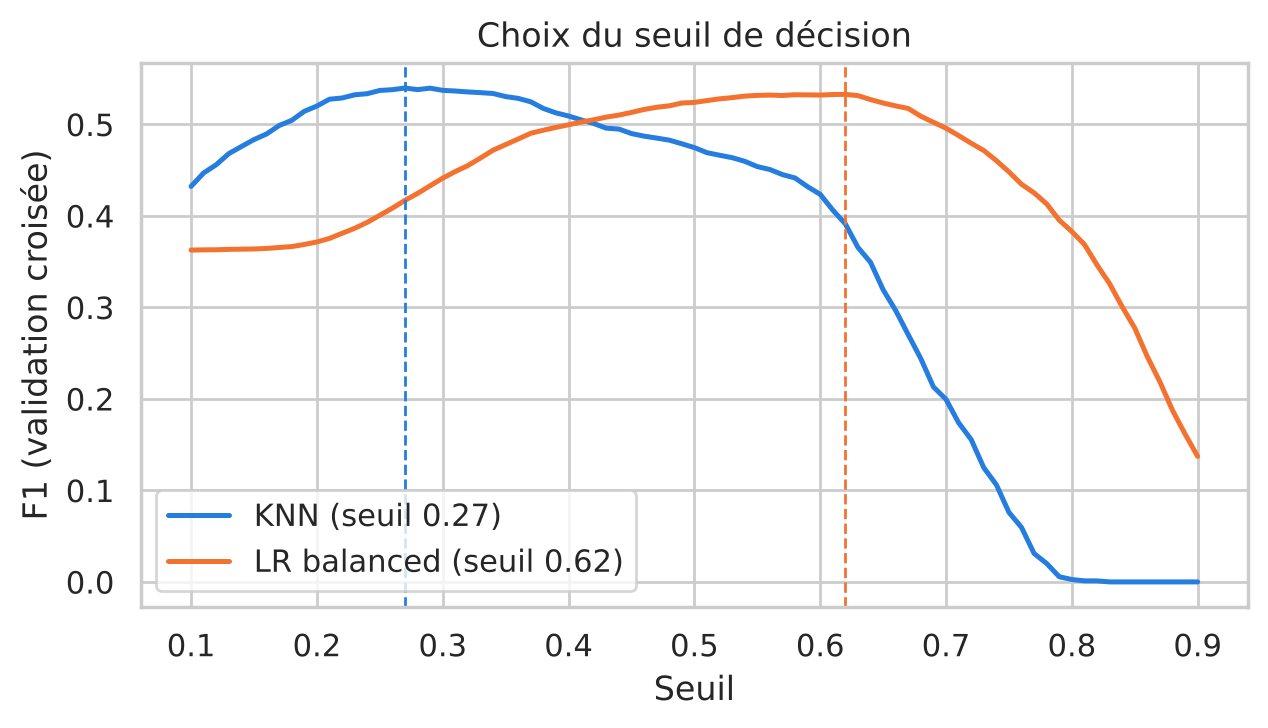

In [29]:
p_train_cv_knn = cross_val_predict(knn_final, X_train_knn, y_train, cv=cv,
                                   method="predict_proba", n_jobs=-1)[:, 1]

f1s_knn = [f1_score(y_train, (p_train_cv_knn >= s).astype(int)) for s in seuils]
seuil_knn = round(float(seuils[np.argmax(f1s_knn)]), 2)
print("Seuil retenu pour le KNN :", seuil_knn, "| seuil de la LR :", best_seuil)
print(f"F1 maximal en validation croisée : KNN {max(f1s_knn):.3f} | LR {max(f1s):.3f}")

plt.figure(figsize=(6.5, 3.8))
plt.plot(seuils, f1s_knn, color=COL_KNN, lw=1.8, label=f"KNN (seuil {seuil_knn})")
plt.plot(seuils, f1s, color=COL_LR, lw=1.8, label=f"LR balanced (seuil {best_seuil})")
plt.axvline(seuil_knn, ls="--", c=COL_KNN, lw=1)
plt.axvline(best_seuil, ls="--", c=COL_LR, lw=1)
plt.xlabel("Seuil"); plt.ylabel("F1 (validation croisée)")
plt.title("Choix du seuil de décision")
plt.legend(); plt.tight_layout(); plt.show()

Le seuil optimal du KNN est beaucoup plus bas que celui de la LR. C'est logique : les probabilités du KNN ne sont pas « rééquilibrées », elles reflètent le vrai taux de défaut (22 %). La LR `balanced`, elle, gonfle les probabilités de défaut pendant l'entraînement, d'où un seuil au-dessus de 0,5. Les deux courbes atteignent pourtant un F1 maximal très proche.

### 11.5 Évaluation finale sur le test

In [30]:
results.append(evaluate("KNN final (pas à pas + seuil optimisé)", y_test, p_knn, seuil_knn))
pd.DataFrame(results).set_index("Modèle").round(3)

,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785
KNN k=5,0.50,0.704,0.408,0.514,0.339,0.783
KNN optimisé (30 variables),0.50,0.763,0.385,0.684,0.268,0.811
KNN + filtre corrélation (17 var.),0.50,0.769,0.461,0.643,0.359,0.814
KNN + sélection pas à pas (6 var.),0.50,0.766,0.471,0.664,0.365,0.819
KNN final (pas à pas + seuil optimisé),0.27,0.766,0.530,0.489,0.578,0.773


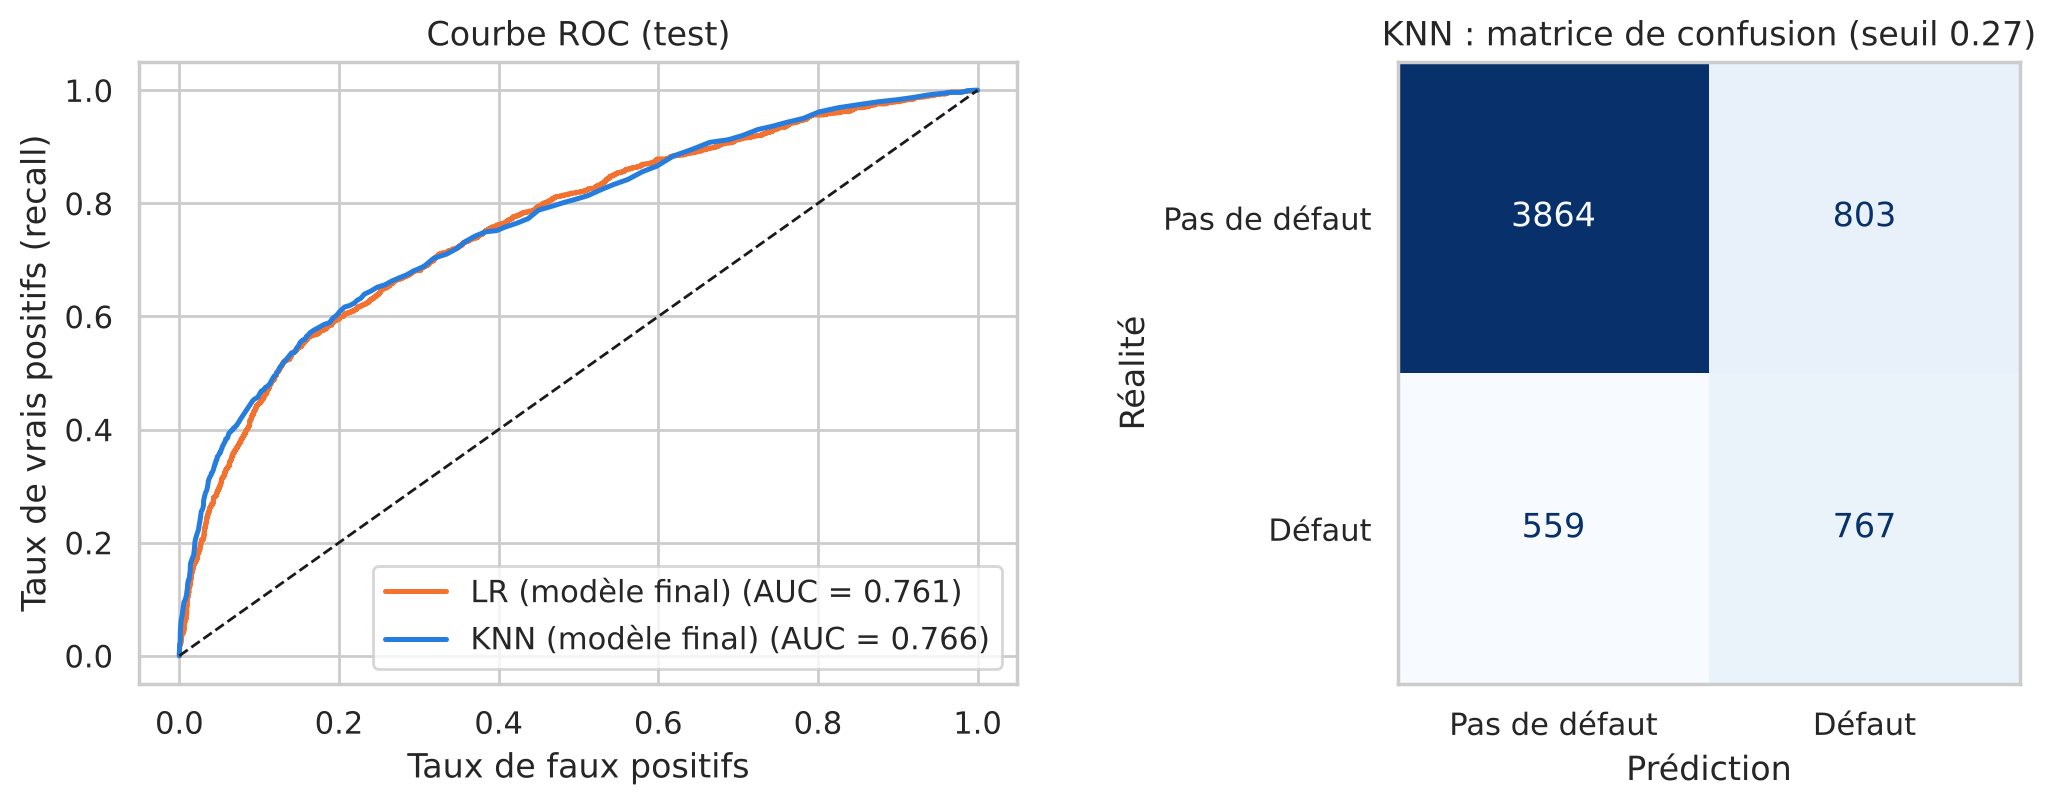

Défauts détectés : 767 sur 1326 (58%)
Défauts manqués : 559 | Fausses alertes : 803


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for nom, proba, couleur in [("LR (modèle final)", p_best, COL_LR), ("KNN (modèle final)", p_knn, COL_KNN)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, color=couleur, lw=1.8, label=f"{nom} (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("Taux de faux positifs"); axes[0].set_ylabel("Taux de vrais positifs (recall)")
axes[0].set_title("Courbe ROC (test)"); axes[0].legend(loc="lower right")

cm_knn = confusion_matrix(y_test, (p_knn >= seuil_knn).astype(int))
ConfusionMatrixDisplay(cm_knn, display_labels=["Pas de défaut", "Défaut"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_xlabel("Prédiction"); axes[1].set_ylabel("Réalité"); axes[1].grid(False)
axes[1].set_title(f"KNN : matrice de confusion (seuil {seuil_knn})")

plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm_knn.ravel()
print(f"Défauts détectés : {tp} sur {tp + fn} ({tp / (tp + fn):.0%})")
print(f"Défauts manqués : {fn} | Fausses alertes : {fp}")

## 12. Qualité des probabilités de défaut (méthode de Yeh & Lien, 2009)

Le papier d'origine du jeu de données (Yeh & Lien, 2009) insiste sur un point : pour la gestion du risque, **une probabilité de défaut fiable vaut plus qu'une simple classification** défaut / pas défaut. Une banque s'en sert pour fixer les plafonds, les taux ou les provisions. On reprend donc les deux outils du papier pour pouvoir comparer nos résultats aux siens.

### 12.1 Lift chart et *area ratio*

On trie les clients du test du plus risqué au moins risqué (selon le modèle) et on compte le nombre cumulé de défauts trouvés.
- **Modèle parfait** : tous les défauts sont en tête de liste.
- **Base** (diagonale) : clients triés au hasard.

$$\text{Area ratio} = \frac{\text{aire entre la courbe du modèle et la diagonale}}{\text{aire entre la courbe parfaite et la diagonale}}$$

C'est la métrique de classement du papier : 0 = hasard, 1 = parfait. Elle est égale au **coefficient de Gini = 2 × AUC − 1**, ce qu'on vérifie ci-dessous.

*Résultats du papier sur leurs données de validation : KNN 0,45 ; LR 0,44 ; réseau de neurones 0,54 (le meilleur des 6 modèles).*

KNN final    area ratio = 0.532 | 2·AUC − 1 = 0.532
LR balanced  area ratio = 0.522 | 2·AUC − 1 = 0.522


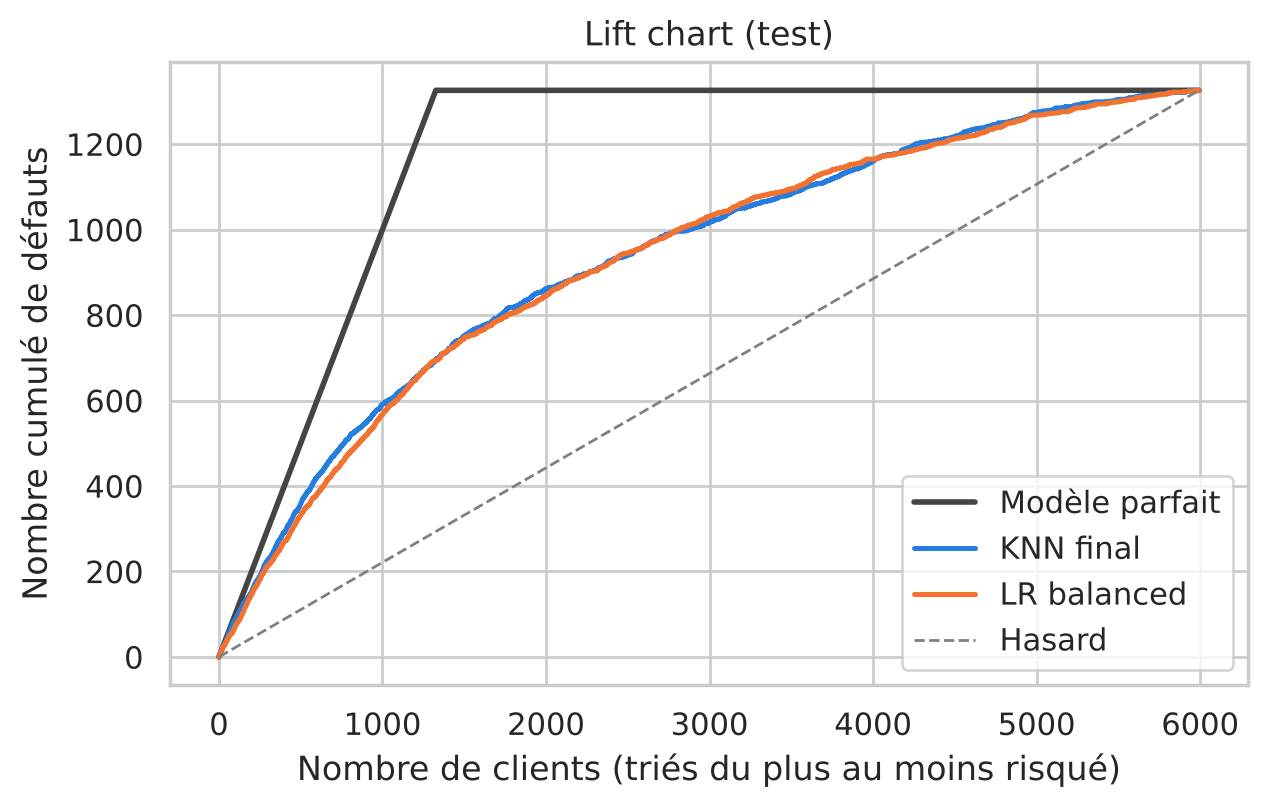

In [32]:
def courbe_lift(y_true, proba):
    """Nombre cumulé de défauts quand on parcourt les clients du plus risqué au moins risqué."""
    ordre = np.argsort(-proba, kind="mergesort")
    return np.concatenate([[0], np.cumsum(np.asarray(y_true)[ordre])])

def aire(courbe):
    """Aire sous une courbe échantillonnée à chaque client (méthode des trapèzes)."""
    return ((courbe[:-1] + courbe[1:]) / 2).sum()

def area_ratio(y_true, proba):
    cum = courbe_lift(y_true, proba)
    n, n_def = len(cum) - 1, cum[-1]
    parfait = np.minimum(np.arange(n + 1), n_def)
    base = n * n_def / 2
    return (aire(cum) - base) / (aire(parfait) - base)

for nom, proba in [("KNN final", p_knn), ("LR balanced", p_best)]:
    print(f"{nom:12s} area ratio = {area_ratio(y_test, proba):.3f} | 2·AUC − 1 = {2 * roc_auc_score(y_test, proba) - 1:.3f}")

# Lift chart, comme les figures 2 à 7 du papier
n, n_def = len(y_test), int(y_test.sum())
x = np.arange(n + 1)
plt.figure(figsize=(6.5, 4.2))
plt.plot(x, np.minimum(x, n_def), c="#444444", lw=2, label="Modèle parfait")
plt.plot(x, courbe_lift(y_test, p_knn), c=COL_KNN, lw=1.8, label="KNN final")
plt.plot(x, courbe_lift(y_test, p_best), c=COL_LR, lw=1.8, label="LR balanced")
plt.plot([0, n], [0, n_def], c="grey", ls="--", lw=1, label="Hasard")
plt.xlabel("Nombre de clients (triés du plus au moins risqué)")
plt.ylabel("Nombre cumulé de défauts")
plt.title("Lift chart (test)")
plt.legend(); plt.tight_layout(); plt.show()

Notre KNN atteint un area ratio de **0,53**, bien au-dessus du KNN du papier (0,45) et proche de leur meilleur modèle (réseau de neurones, 0,54). La LR `balanced` est aussi au-dessus de la LR du papier (0,52 contre 0,44). Notre prétraitement et notre feature engineering paient donc pour les deux modèles.

⚠️ La comparaison reste indicative : le papier ne travaille pas exactement sur le même échantillon (25 000 clients et un autre découpage train / validation) et ne détaille pas son prétraitement.

### 12.2 Les probabilités prédites sont-elles réalistes ? *Sorting Smoothing Method*

On ne connaît pas la « vraie » probabilité de défaut d'un client, seulement s'il a fait défaut (1) ou non (0). Le papier propose de l'estimer ainsi :
1. trier les clients du test selon la probabilité prédite ;
2. estimer la vraie probabilité de chaque client par le taux de défaut observé parmi ses voisins dans ce classement (les *n* = 50 clients avant et après lui, soit une fenêtre de 101 clients) ;
3. faire la régression linéaire **vraie PD = A + B × PD prédite**.

Les probabilités sont fiables si **R² ≈ 1, A ≈ 0 et B ≈ 1** (les points suivent la diagonale).

On ajoute le **score de Brier** : l'erreur quadratique moyenne entre la probabilité prédite et le résultat réel (0 ou 1), plus il est bas, mieux c'est. Pour référence, prédire 22 % pour tout le monde donne un Brier d'environ 0,172.

*Résultats du papier (tableau 2) : KNN B = 0,770 ; A = 0,052 ; R² = 0,876. Réseau de neurones (le meilleur) : B = 0,998 ; A = 0,015 ; R² = 0,965.*

On compare le KNN aux deux versions de la régression logistique : la LR `balanced` (modèle final de la partie 1) et la LR baseline (sans pondération des classes).

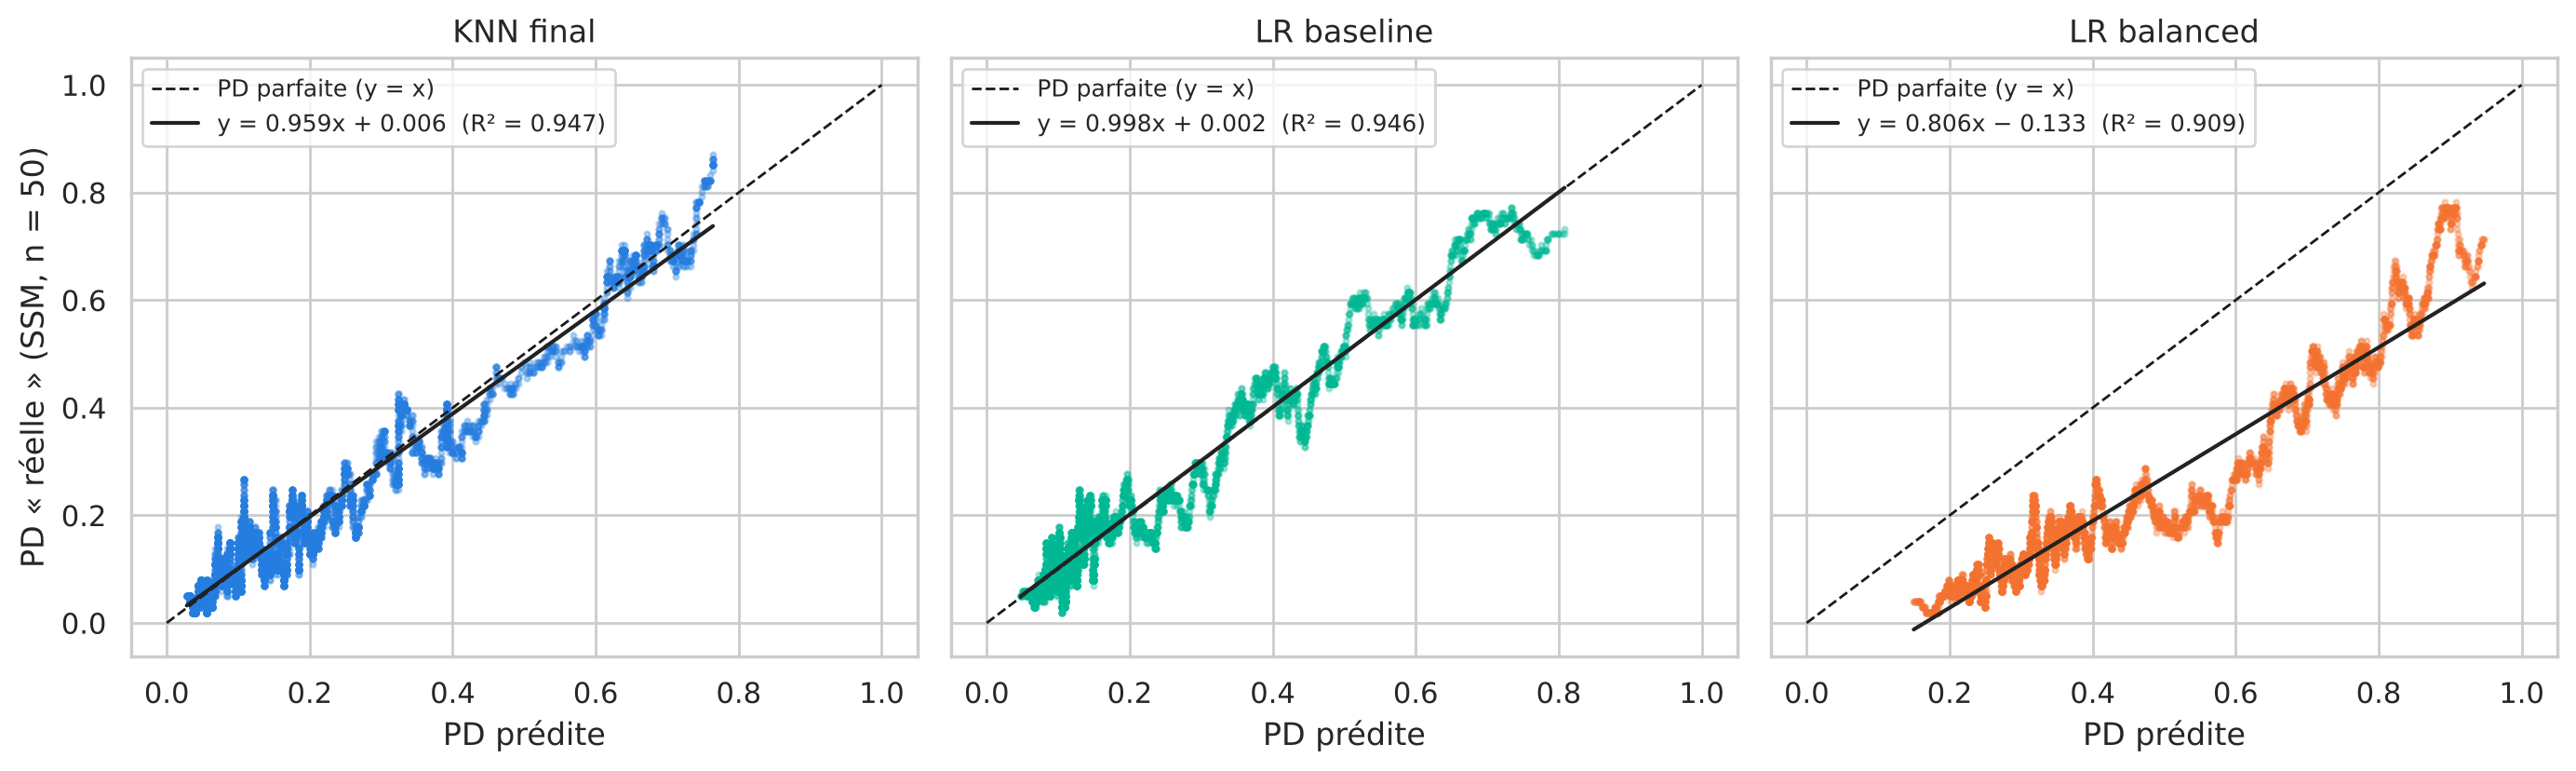

Taux de défaut réel sur le test : 0.221


,Area ratio,SSM : pente B,SSM : ordonnée A,SSM : R²,Brier,PD moyenne prédite
Modèle,,,,,,
KNN final,0.532,0.959,0.006,0.947,0.137,0.224
LR baseline,0.516,0.998,0.002,0.946,0.141,0.220
LR balanced,0.522,0.806,-0.133,0.909,0.191,0.437


In [33]:
def sorting_smoothing(y_true, proba, n=50):
    """Sorting Smoothing Method (Yeh & Lien, 2009) : vraie PD estimée par moyenne mobile de la cible."""
    ordre = np.argsort(proba, kind="mergesort")
    pd_predite = proba[ordre]
    pd_reelle = pd.Series(np.asarray(y_true)[ordre]).rolling(2 * n + 1, center=True).mean().to_numpy()
    garde = ~np.isnan(pd_reelle)      # les n premiers et n derniers clients n'ont pas de fenêtre complète
    return pd_predite[garde], pd_reelle[garde]

modeles_pd = [("KNN final", p_knn, COL_KNN),
              ("LR baseline", p_base, COL_LR_BASE),
              ("LR balanced", p_best, COL_LR)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharex=True, sharey=True)
qualite_pd = []
for ax, (nom, proba, couleur) in zip(axes, modeles_pd):
    x_pred, y_reel = sorting_smoothing(y_test, proba)
    B, A = np.polyfit(x_pred, y_reel, 1)
    r2 = np.corrcoef(x_pred, y_reel)[0, 1] ** 2
    qualite_pd.append({"Modèle": nom,
                       "Area ratio": area_ratio(y_test, proba),
                       "SSM : pente B": B, "SSM : ordonnée A": A, "SSM : R²": r2,
                       "Brier": brier_score_loss(y_test, proba),
                       "PD moyenne prédite": proba.mean()})

    ax.scatter(x_pred, y_reel, s=4, alpha=0.3, color=couleur)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="PD parfaite (y = x)")
    grille = np.linspace(x_pred.min(), x_pred.max(), 50)
    ax.plot(grille, A + B * grille, color="#222222", lw=1.5,
            label=f"y = {B:.3f}x {'+' if A >= 0 else '−'} {abs(A):.3f}  (R² = {r2:.3f})")
    ax.set_title(nom); ax.set_xlabel("PD prédite"); ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("PD « réelle » (SSM, n = 50)")
plt.tight_layout(); plt.show()

print(f"Taux de défaut réel sur le test : {y_test.mean():.3f}")
pd.DataFrame(qualite_pd).set_index("Modèle").round(3)

**Lecture :**
- Les probabilités du **KNN** suivent la diagonale : pente B ≈ 0,96, ordonnée A ≈ 0,01, R² ≈ 0,95. C'est bien mieux que le KNN du papier (B = 0,770 ; A = 0,052 ; R² = 0,876) et proche de leur meilleur modèle, le réseau de neurones (B = 0,998 ; R² = 0,965). Deux raisons probables : le grand nombre de voisins (*k* = 250), qui donne une probabilité calculée sur beaucoup de clients donc stable, et le prétraitement (standardisation, log, one-hot, sélection des variables). Le KNN a aussi le **meilleur score de Brier** (0,137).
- La **LR baseline** est elle aussi bien calibrée (B ≈ 1,00 ; A ≈ 0,00 ; R² ≈ 0,95) : sur ce critère, elle fait jeu égal avec le KNN.
- La **LR `balanced`** classe bien les clients (area ratio 0,52), mais ses probabilités sont **surestimées** : PD moyenne de 0,44 pour un taux réel de 0,22, d'où une ordonnée A ≈ −0,13. Son Brier (0,191) est même moins bon que celui d'un modèle naïf qui prédit 22 % pour tout le monde (0,172). La pondération des classes aide la classification, mais ses sorties sont des scores et non de vraies probabilités de défaut.

**Conséquence pour le projet :** pour donner une PD à la banque, il faut utiliser le KNN, la LR baseline, ou recalibrer la LR `balanced`. Pour décider défaut / pas défaut, la LR `balanced` reste valable car le seuil corrige ce décalage.

## 13. Interprétation : importance des variables par permutation

Le KNN n'a pas de coefficients. Pour savoir quelles variables comptent, on utilise l'**importance par permutation** : on mélange au hasard les valeurs d'une variable (ce qui casse son lien avec le défaut) et on mesure la baisse d'AUC. Plus la baisse est forte, plus le modèle s'appuie sur cette variable.

Le calcul se fait **en validation croisée sur le train** : dans chacun des 5 plis, le KNN retenu est entraîné sur 4/5 du train et la permutation est faite sur le 5ᵉ cinquième. Le test reste réservé à l'évaluation finale, et les 5 plis montrent si l'importance d'une variable est stable ou due au hasard.

⚠️ Quand deux variables portent la même information, mélanger l'une seule fait peu baisser l'AUC car l'autre compense : leur importance est sous-estimée. La sélection pas à pas limite ce problème, puisqu'elle écarte déjà les variables redondantes.

⏱ Environ 1 minute.

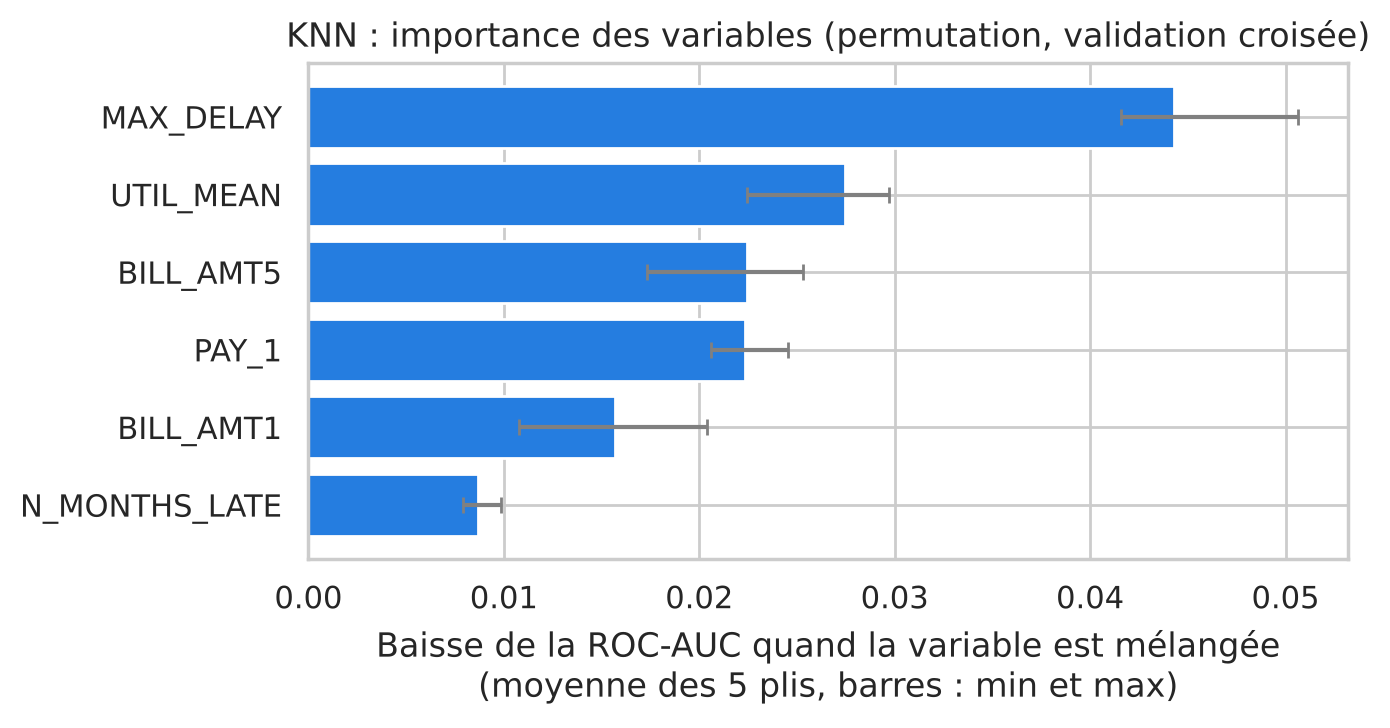

,baisse_AUC,min_plis,max_plis
MAX_DELAY,0.0443,0.0416,0.0507
UTIL_MEAN,0.0275,0.0224,0.0297
BILL_AMT5,0.0224,0.0173,0.0253
PAY_1,0.0223,0.0206,0.0246
BILL_AMT1,0.0157,0.0108,0.0204
N_MONTHS_LATE,0.0087,0.0079,0.0099


In [34]:
y_train_arr = y_train.to_numpy()
imp_plis = []
for i_train, i_valid in cv.split(X_train_knn, y_train_arr):
    modele = clone(knn_final).fit(X_train_knn[i_train], y_train_arr[i_train])
    perm = permutation_importance(modele, X_train_knn[i_valid], y_train_arr[i_valid], scoring="roc_auc",
                                  n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    imp_plis.append(perm.importances_mean)

imp_plis = pd.DataFrame(imp_plis, columns=vars_knn)
imp_knn = (pd.DataFrame({"baisse_AUC": imp_plis.mean(),
                         "min_plis": imp_plis.min(),
                         "max_plis": imp_plis.max()})
           .sort_values("baisse_AUC", ascending=False))

top = imp_knn.iloc[::-1]
plt.figure(figsize=(7, 3.8))
plt.barh(top.index, top["baisse_AUC"], color=COL_KNN,
         xerr=[top["baisse_AUC"] - top["min_plis"], top["max_plis"] - top["baisse_AUC"]], ecolor="grey", capsize=3)
plt.axvline(0, c="k", lw=0.8)
plt.xlabel("Baisse de la ROC-AUC quand la variable est mélangée\n(moyenne des 5 plis, barres : min et max)")
plt.title("KNN : importance des variables (permutation, validation croisée)")
plt.tight_layout(); plt.show()

imp_knn.round(4)

**Lecture :**
- Les 6 variables sont utiles dans **les 5 plis** : la baisse d'AUC reste positive même dans le pli le plus défavorable. Aucune n'a donc été retenue par hasard.
- Le **pire retard** (`MAX_DELAY`) est la variable la plus importante, suivie du **taux d'utilisation** (`UTIL_MEAN`). Ce sont deux variables que nous avons construites : notre feature engineering est au cœur du modèle.
- Viennent ensuite le **retard le plus récent** (`PAY_1`) et les **montants des relevés** de mai et de septembre (`BILL_AMT5`, `BILL_AMT1`), qui complètent `UTIL_MEAN` sur le niveau et l'évolution de la dette.
- `N_MONTHS_LATE` paraît moins importante, alors que la sélection l'a choisie en premier. Ce n'est pas contradictoire : seule, c'est la meilleure variable, mais une fois `MAX_DELAY` et `PAY_1` présentes, son information est en grande partie redondante (voir l'avertissement ci-dessus).
- Comme pour la régression logistique, **les retards de paiement dominent**. Le KNN s'appuie en plus sur le niveau de dette (utilisation et relevés), probablement parce qu'il capte des effets non linéaires, par exemple un client proche de son plafond.

## 14. Comparaison régression logistique / KNN

In [35]:
res = pd.DataFrame(results).set_index("Modèle")
res.round(3)

,Seuil,ROC-AUC,F1,Précision,recall,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785
KNN k=5,0.50,0.704,0.408,0.514,0.339,0.783
KNN optimisé (30 variables),0.50,0.763,0.385,0.684,0.268,0.811
KNN + filtre corrélation (17 var.),0.50,0.769,0.461,0.643,0.359,0.814
KNN + sélection pas à pas (6 var.),0.50,0.766,0.471,0.664,0.365,0.819
KNN final (pas à pas + seuil optimisé),0.27,0.766,0.530,0.489,0.578,0.773


In [36]:
finaux = {"LR balanced + seuil optimisé": (p_best, best_seuil, X_train_s.shape[1]),
          "KNN final (pas à pas + seuil optimisé)": (p_knn, seuil_knn, len(vars_knn))}

y_test_arr = y_test.to_numpy()
comparaison = []
for nom, (proba, seuil, nb) in finaux.items():
    ligne = evaluate(nom, y_test, proba, seuil)
    ligne["Nb variables"] = nb
    ligne["Area ratio"] = area_ratio(y_test, proba)
    ligne["Brier"] = brier_score_loss(y_test, proba)
    ligne["Défauts manqués (FN)"] = int(((proba < seuil) & (y_test_arr == 1)).sum())
    ligne["Fausses alertes (FP)"] = int(((proba >= seuil) & (y_test_arr == 0)).sum())
    comparaison.append(ligne)

pd.DataFrame(comparaison).set_index("Modèle").drop(columns="Accuracy").round(3)

,Seuil,ROC-AUC,F1,Précision,recall,Nb variables,Area ratio,Brier,Défauts manqués (FN),Fausses alertes (FP)
Modèle,,,,,,,,,,
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,30,0.522,0.191,610,678
KNN final (pas à pas + seuil optimisé),0.27,0.766,0.530,0.489,0.578,6,0.532,0.137,559,803


### Conclusion sur le KNN

**Modèle retenu :** *k* = 250 voisins, distance de Manhattan, pondération uniforme, 6 variables choisies par sélection pas à pas (`N_MONTHS_LATE`, `UTIL_MEAN`, `PAY_1`, `BILL_AMT1`, `BILL_AMT5`, `MAX_DELAY`), seuil 0,27.

- **Le réglage est indispensable.** Avec les paramètres par défaut (*k* = 5), le KNN est nettement moins bon que la régression logistique (AUC 0,704 contre 0,761). Avec beaucoup de voisins, la distance de Manhattan et une sélection des variables, il fait jeu égal avec elle (AUC 0,766).
- **6 variables suffisent.** Le modèle à 6 variables fait aussi bien que celui à 17 (AUC test 0,766 contre 0,769, écart non significatif) et que la LR, qui en utilise 30.
- **Classification.** Au seuil optimisé, le KNN a un F1 proche de la LR (0,530 contre 0,526). Il détecte plus de défauts (recall 0,578 contre 0,540, soit 51 défauts manqués en moins), au prix de 125 fausses alertes en plus (précision 0,489 contre 0,514). Comme rater un défaut coûte plus cher à la banque qu'une fausse alerte, ce compromis plutôt favorable au KNN reste à confirmer avec de vrais coûts.
- **Écart faible.** Le gain d'AUC sur la LR (+0,005) est bien plus petit que la variation d'un pli à l'autre (écart-type de 0,008) : on ne peut pas dire que le KNN classe mieux les clients que la LR.
- **Probabilités de défaut : le vrai point fort du KNN.** Ses PD sont réalistes (SSM : B ≈ 0,96 ; A ≈ 0,01 ; R² ≈ 0,95) et il a le meilleur Brier (0,137), alors que la LR `balanced` surestime fortement les PD. Sur ce critère, mis en avant par le papier, notre KNN est proche de leur meilleur modèle.
- **Variables clés.** Pire retard, taux d'utilisation, retard récent et montants des relevés. Deux des trois variables les plus importantes (`MAX_DELAY`, `UTIL_MEAN`) viennent de notre feature engineering.

**Limites :**
- Le KNN garde en mémoire les ~24 000 clients du train et calcule toutes les distances à chaque prédiction : il est lent pour scorer un grand portefeuille. La sélection à 6 variables réduit ce coût.
- Il ne donne pas de formule interprétable (pas de coefficients) : l'importance par permutation n'en donne qu'une vision globale.
- La sélection pas à pas est gloutonne (elle ne revient jamais sur un choix) et son score en validation croisée est optimiste. Une validation croisée imbriquée donnerait une estimation sans biais, mais elle serait 5 fois plus longue.
- L'essentiel de l'information est dans les retards de paiement, qu'un modèle linéaire capte déjà bien. D'où un gain limité sur la classification.

**Pistes d'amélioration :**
- Donner des poids différents aux variables dans la distance.
- Recalibrer les probabilités des autres modèles (LR `balanced`, Random Forest, XGBoost…) pour les comparer au KNN sur la qualité des PD.